In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from study_config import *

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

d = pd.read_csv(PROC / "retail_clean_flagged.csv", parse_dates=["date"])

MIN_M = 6            # minimum months a series needs in EACH period being compared
B_BOOT = 1000        # bootstrap resamples
KEY = {"Pre-pandemic": "pre", "Pandemic": "pan", "Post-pandemic": "post"}
d["p"] = d["period"].map(KEY)
print(d["p"].value_counts().to_dict())

{'pan': 104527, 'post': 94566, 'pre': 8508}


In [2]:
ids = ["market_id", "commodity_id", "category", "commodity", "market", "admin1"]
g = (d.groupby(ids + ["p"])
       .agg(months=("price", "size"), mean_price=("price", "mean")).reset_index())
w = g.pivot(index=ids, columns="p", values=["months", "mean_price"])
w.columns = [f"{a}_{b}" for a, b in w.columns]
w = w.reset_index()
print("Commodity-market series with data:", len(w))

Commodity-market series with data: 4589


In [3]:
def matched(a, b):
    m = w[(w[f"months_{a}"] >= MIN_M) & (w[f"months_{b}"] >= MIN_M)].copy()
    m["p1"], m["p2"] = m[f"mean_price_{a}"], m[f"mean_price_{b}"]
    m["log_chg"] = np.log(m["p2"] / m["p1"])
    m["pct_chg"] = (np.exp(m["log_chg"]) - 1) * 100
    return m

M = {"pre_pan": matched("pre", "pan"),
     "pan_post": matched("pan", "post"),
     "pre_post": matched("pre", "post")}
for k, m in M.items():
    m.to_csv(TAB / f"10_matched_series_{k}.csv", index=False)

summ = pd.DataFrame([{"comparison": k, "series": len(m), "markets": m["market_id"].nunique(),
                      "commodities": m["commodity"].nunique(), "regions": m["admin1"].nunique(),
                      "categories": m["category"].nunique(),
                      "median_pct_change": round(m["pct_chg"].median(), 1),
                      "share_rising_pct": round((m["pct_chg"] > 0).mean() * 100, 1)}
                     for k, m in M.items()])
display(summ)
print("Markets and regions behind the pre-pandemic comparisons:")
print(M["pre_pan"].groupby(["admin1", "market"]).size())

,comparison,series,markets,commodities,regions,categories,median_pct_change,share_rising_pct
0,pre_pan,38,3,14,3,4,43.9,94.7
1,pan_post,2615,83,59,17,4,18.8,92.1
2,pre_post,36,3,14,3,4,73.4,100.0


Markets and regions behind the pre-pandemic comparisons:
admin1                   market        
National Capital region  Metro Manila      14
Region IX                Zamboanga City    12
Region XI                Davao City        12
dtype: int64


In [4]:
def boot_ci(m, B=B_BOOT, seed=42):
    """95% CI of the median % change, resampling whole MARKETS (series within a market are correlated)."""
    rng = np.random.default_rng(seed)
    cl = m.groupby("market_id")["pct_chg"].apply(np.array)
    vals = [np.median(np.concatenate([cl.iloc[i] for i in rng.integers(0, len(cl), len(cl))]))
            for _ in range(B)]
    return np.percentile(vals, [2.5, 97.5])

P = M["pan_post"]
lo, hi = boot_ci(P)
print(f"Overall: median {P['pct_chg'].median():.1f}% | 95% CI [{lo:.1f}, {hi:.1f}]")

cat = P.groupby("category").agg(series=("pct_chg", "size"), markets=("market_id", "nunique"),
                                median_pct=("pct_chg", "median"),
                                share_rising=("pct_chg", lambda x: (x > 0).mean() * 100)).round(1)
for c in cat.index:
    l, h = boot_ci(P[P["category"] == c])
    cat.loc[c, "ci_low"], cat.loc[c, "ci_high"] = round(l, 1), round(h, 1)
display(cat)

reg = (P.groupby("admin1").agg(series=("pct_chg", "size"), markets=("market_id", "nunique"),
                               median_pct=("pct_chg", "median")).round(1).sort_values("median_pct"))
display(reg)

com = (P.groupby(["category", "commodity"])
         .agg(series=("pct_chg", "size"), median_price_pandemic=("p1", "median"),
              median_price_post=("p2", "median"), median_pct=("pct_chg", "median")).round(1))
com10 = com[com["series"] >= 10].sort_values("median_pct")
print(f"Commodities: {len(com)} | with >= 10 series: {len(com10)}")
print("Smallest increases:"); display(com10.head(5))
print("Largest increases:");  display(com10.tail(5))

mk = P.groupby(["admin1", "market"]).agg(series=("pct_chg", "size"), median_pct=("pct_chg", "median")).round(1)
print("Markets:", len(mk))

cat.to_csv(TAB / "10_pan_post_by_category.csv"); reg.to_csv(TAB / "10_pan_post_by_region.csv")
com.to_csv(TAB / "10_pan_post_by_commodity.csv"); mk.to_csv(TAB / "10_pan_post_by_market.csv")

Overall: median 18.8% | 95% CI [18.0, 19.6]


,series,markets,median_pct,share_rising,ci_low,ci_high
category,,,,,,
cereals and tubers,370,83,21.4,98.9,20.4,23.1
"meat, fish and eggs",915,83,16.0,92.3,15.2,16.7
pulses and nuts,110,68,11.2,87.3,8.5,13.0
vegetables and fruits,1220,83,22.6,90.2,21.2,24.7


,series,markets,median_pct
admin1,,,
Autonomous region in Muslim Mindanao,120,5,12.5
Region IV-B,161,5,16.3
Region VII,114,4,16.5
Region IV-A,179,5,17.3
National Capital region,43,1,17.3
Region IX,144,4,17.6
Region VIII,199,6,18.0
Region XIII,161,5,18.8
Region I,120,4,19.1


Commodities: 59 | with >= 10 series: 52
Smallest increases:


series  median_price_pandemic  \
category              commodity                                          
vegetables and fruits Onions (red)           67                  160.8   
meat, fish and eggs   Shrimp (endeavor)      17                  406.6   
                      Shrimp (tiger)         56                  550.3   
pulses and nuts       Beans (mung)           54                  100.0   
vegetables and fruits Bananas (saba)         25                   37.6   

                                         median_price_post  median_pct  
category              commodity                                         
vegetables and fruits Onions (red)                   162.1        -1.3  
meat, fish and eggs   Shrimp (endeavor)              452.7         4.2  
                      Shrimp (tiger)                 573.2         5.4  
pulses and nuts       Beans (mung)                   108.2         8.4  
vegetables and fruits Bananas (saba)                  39.8         8.8

Largest increases:


series  median_price_pandemic  \
category              commodity                                             
vegetables and fruits Tomatoes                  76                   68.6   
                      Beans (green, fresh)      37                   92.3   
cereals and tubers    Potatoes (Irish)          76                   99.9   
vegetables and fruits Choko                     51                   36.4   
                      Carrots                   76                   96.1   

                                            median_price_post  median_pct  
category              commodity                                            
vegetables and fruits Tomatoes                           92.0        36.2  
                      Beans (green, fresh)              127.6        38.0  
cereals and tubers    Potatoes (Irish)                  136.2        38.4  
vegetables and fruits Choko                              50.1        38.4  
                      Carrots                           135.1        42.9

Markets: 83


In [5]:
for k, label in [("pre_pan", "Pre-pandemic -> Pandemic"), ("pre_post", "Pre-pandemic -> Post-pandemic")]:
    m = M[k]
    print(f"\n===== {label} =====")
    print("By market:")
    display(m.groupby("market").agg(series=("pct_chg", "size"), median_pct=("pct_chg", "median"),
            share_rising=("pct_chg", lambda x: (x > 0).mean() * 100)).round(1))
    print("By category:")
    display(m.groupby("category").agg(series=("pct_chg", "size"), commodities=("commodity", "nunique"),
            median_pct=("pct_chg", "median")).round(1))
    print("By commodity:")
    display(m.groupby("commodity").agg(series=("pct_chg", "size"),
            median_pct=("pct_chg", "median")).round(1).sort_values("median_pct"))


===== Pre-pandemic -> Pandemic =====
By market:


,series,median_pct,share_rising
market,,,
Davao City,12,71.1,91.7
Metro Manila,14,24.4,100.0
Zamboanga City,12,52.8,91.7


By category:


,series,commodities,median_pct
category,,,
cereals and tubers,9,3,42.2
"meat, fish and eggs",12,4,35.4
pulses and nuts,3,1,22.5
vegetables and fruits,14,6,88.1


By commodity:


,series,median_pct
commodity,,
"Rice (regular, milled)",3,-0.9
Garlic,1,7.3
Beans (mung),3,22.5
Eggs,3,30.6
"Meat (chicken, whole)",3,34.0
Carrots,3,45.6
Potatoes (Irish),3,47.1
Sweet potatoes,3,56.0
Cabbage,3,61.0


... (2 outputs left out)

By category:


,series,commodities,median_pct
category,,,
cereals and tubers,7,3,61.8
"meat, fish and eggs",12,4,55.8
pulses and nuts,3,1,37.5
vegetables and fruits,14,6,88.6


By commodity:


,series,median_pct
commodity,,
"Rice (regular, milled)",3,16.1
Garlic,1,18.5
"Meat (chicken, whole)",3,36.8
Beans (mung),3,37.5
Eggs,3,53.0
Sweet potatoes,1,61.8
Onions (white),1,77.5
Meat (pork),3,78.4
Onions (red),3,87.8


In [6]:
T = w[(w["months_pre"] >= MIN_M) & (w["months_pan"] >= MIN_M) & (w["months_post"] >= MIN_M)].copy()
T["pre_to_pan"] = (T["mean_price_pan"] / T["mean_price_pre"] - 1) * 100
T["pan_to_post"] = (T["mean_price_post"] / T["mean_price_pan"] - 1) * 100
T["pre_to_post"] = (T["mean_price_post"] / T["mean_price_pre"] - 1) * 100

prof = (T.groupby("commodity")[["pre_to_pan", "pan_to_post", "pre_to_post"]]
          .median().round(1).sort_values("pre_to_post"))
print("Series present in all three periods:", len(T), "| markets:", T["market_id"].nunique())
print("Median across series:", T[["pre_to_pan", "pan_to_post", "pre_to_post"]].median().round(1).to_dict())
display(prof)
prof.to_csv(TAB / "10_three_period_profile.csv")

Series present in all three periods: 36 | markets: 3
Median across series: {'pre_to_pan': 39.0, 'pan_to_post': 17.2, 'pre_to_post': 73.4}


,pre_to_pan,pan_to_post,pre_to_post
commodity,,,
"Rice (regular, milled)",-0.9,17.2,16.1
Garlic,7.3,10.5,18.5
"Meat (chicken, whole)",34.0,6.8,36.8
Beans (mung),22.5,22.8,37.5
Eggs,30.6,21.1,53.0
Sweet potatoes,17.5,37.7,61.8
Onions (white),83.7,-3.4,77.5
Meat (pork),63.1,10.8,78.4
Onions (red),137.9,-18.2,87.8


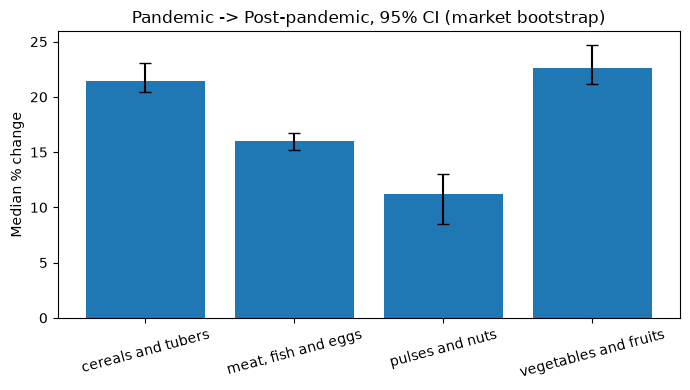

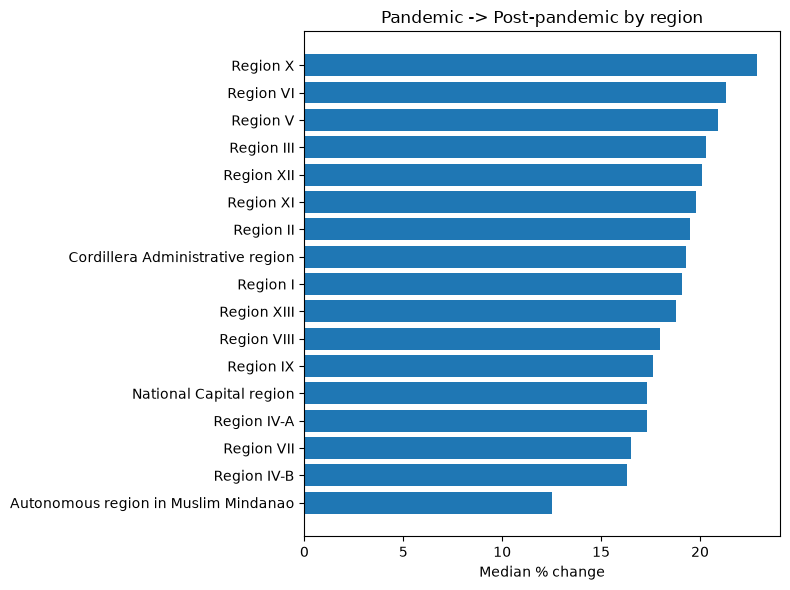

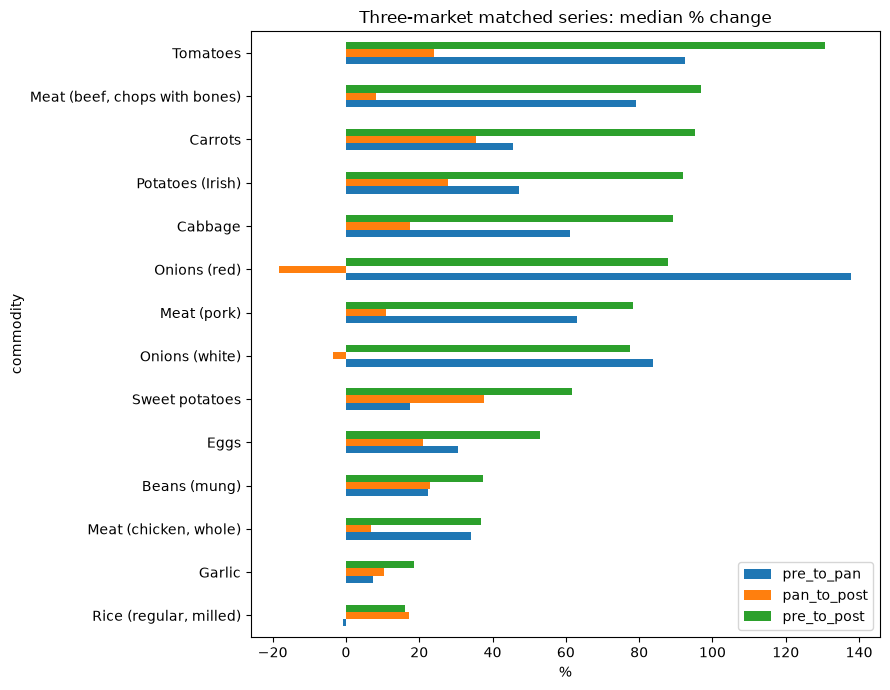

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(cat))
err = [cat["median_pct"] - cat["ci_low"], cat["ci_high"] - cat["median_pct"]]
ax.bar(x, cat["median_pct"], yerr=err, capsize=4)
ax.set_xticks(x); ax.set_xticklabels(cat.index, rotation=15)
ax.set_ylabel("Median % change"); ax.set_title("Pandemic -> Post-pandemic, 95% CI (market bootstrap)")
plt.tight_layout(); plt.savefig(FIG / "10_pan_post_by_category.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(reg.index, reg["median_pct"]); ax.set_xlabel("Median % change")
ax.set_title("Pandemic -> Post-pandemic by region")
plt.tight_layout(); plt.savefig(FIG / "10_pan_post_by_region.png", dpi=150); plt.show()

prof.plot(kind="barh", figsize=(9, 7))
plt.title("Three-market matched series: median % change"); plt.xlabel("%")
plt.tight_layout(); plt.savefig(FIG / "10_three_period_profile.png", dpi=150); plt.show()

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

MIN_MKT, MIN_SER = 3, 5      # a cell is "reliable" with >= 3 markets AND >= 5 matched series
ORDER = ["cereals and tubers", "meat, fish and eggs", "pulses and nuts", "vegetables and fruits"]

P = pd.read_csv(TAB / "10_matched_series_pan_post.csv")

cells = (P.groupby(["admin1", "category"])
           .agg(series=("pct_chg", "size"), markets=("market_id", "nunique"),
                median_pct=("pct_chg", "median")).round(1).reset_index())
cells["reliable"] = (cells["markets"] >= MIN_MKT) & (cells["series"] >= MIN_SER)
cells.to_csv(TAB / "10B_category_region_cells.csv", index=False)

print(f"Cells with data: {len(cells)} of {P['admin1'].nunique() * P['category'].nunique()} | "
      f"reliable: {int(cells['reliable'].sum())}")
display(cells[~cells["reliable"]].sort_values("series"))

Cells with data: 68 of 68 | reliable: 61


,admin1,category,series,markets,median_pct,reliable
10,National Capital region,pulses and nuts,2,1,20.6,False
42,Region VI,pulses and nuts,2,2,14.6,False
26,Region IV-A,pulses and nuts,3,2,16.7,False
66,Region XIII,pulses and nuts,4,2,-0.2,False
8,National Capital region,cereals and tubers,5,1,17.3,False
9,National Capital region,"meat, fish and eggs",17,1,12.4,False
11,National Capital region,vegetables and fruits,19,1,32.7,False


category,cereals and tubers,"meat, fish and eggs",pulses and nuts,vegetables and fruits,All categories
Autonomous region in Muslim Mindanao,15.4,14.3,12.3,10.4,12.5
Cordillera Administrative region,21.5,15.7,9.4,25.0,19.3
National Capital region,17.3,12.4,20.6,32.7,17.3
Region I,19.1,18.4,9.1,22.8,19.1
Region II,18.7,16.7,20.9,33.2,19.5
Region III,20.7,16.4,13.5,33.6,20.3
Region IV-A,18.7,13.2,16.7,24.5,17.3
Region IV-B,19.1,16.5,15.0,15.4,16.3
Region IX,23.2,12.1,10.9,18.8,17.6
Region V,24.7,16.6,12.7,27.6,20.9


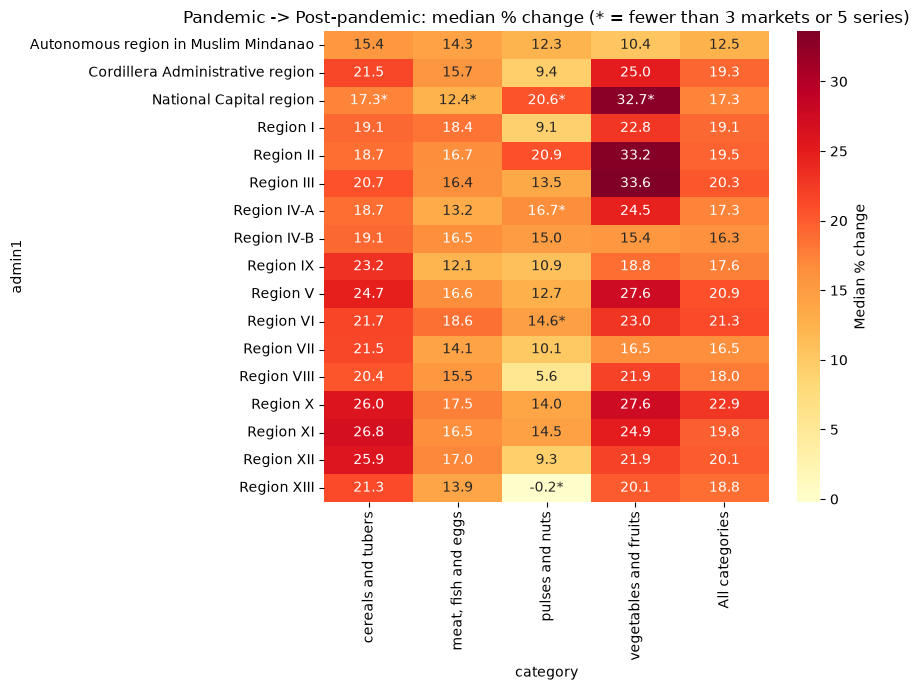

Lowest reliable cells:


,admin1,category,series,markets,median_pct,reliable
50,Region VIII,pulses and nuts,11,6,5.6,True
14,Region I,pulses and nuts,5,3,9.1,True
62,Region XII,pulses and nuts,6,3,9.3,True


Highest reliable cells:


,admin1,category,series,markets,median_pct,reliable
55,Region X,vegetables and fruits,78,5,27.6,True
19,Region II,vegetables and fruits,48,4,33.2,True
23,Region III,vegetables and fruits,117,7,33.6,True


Regions with all 4 categories reliable: 13
Range across regions (reliable cells only):


,min,max
category,,
cereals and tubers,15.4,26.8
"meat, fish and eggs",12.1,18.6
pulses and nuts,5.6,20.9
vegetables and fruits,10.4,33.6


In [2]:
mat = cells.pivot(index="admin1", columns="category", values="median_pct")[ORDER]
rel = cells.pivot(index="admin1", columns="category", values="reliable")[ORDER]
mat["All categories"] = P.groupby("admin1")["pct_chg"].median().round(1)

allrow = P.groupby("category")["pct_chg"].median().round(1)[ORDER]
allrow["All categories"] = round(P["pct_chg"].median(), 1)
full = pd.concat([mat, allrow.to_frame("All regions").T])
display(full)
full.to_csv(TAB / "10B_category_region_matrix.csv")

ann = mat.copy().astype(object)
for r in mat.index:
    for c in ORDER:
        v = mat.loc[r, c]
        ann.loc[r, c] = "" if pd.isna(v) else f"{v:.1f}" + ("" if rel.loc[r, c] else "*")
    ann.loc[r, "All categories"] = f"{mat.loc[r, 'All categories']:.1f}"

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(mat, annot=ann, fmt="", cmap="YlOrRd", cbar_kws={"label": "Median % change"}, ax=ax)
ax.set_title("Pandemic -> Post-pandemic: median % change (* = fewer than 3 markets or 5 series)")
plt.tight_layout(); plt.savefig(FIG / "10B_category_region_matrix.png", dpi=150); plt.show()

r = cells[cells["reliable"]].sort_values("median_pct")
print("Lowest reliable cells:"); display(r.head(3))
print("Highest reliable cells:"); display(r.tail(3))
print("Regions with all 4 categories reliable:", int(rel.fillna(False).all(axis=1).sum()))
print("Range across regions (reliable cells only):")
display(r.groupby("category")["median_pct"].agg(["min", "max"]).loc[ORDER])

In [3]:
for k, label in [("pre_pan", "Pre-pandemic -> Pandemic"), ("pre_post", "Pre-pandemic -> Post-pandemic")]:
    m = pd.read_csv(TAB / f"10_matched_series_{k}.csv")
    t = (m.groupby(["admin1", "category"])
           .agg(series=("pct_chg", "size"), commodities=("commodity", "nunique"),
                median_pct=("pct_chg", "median")).round(1).reset_index())
    t.to_csv(TAB / f"10B_{k}_by_region_category.csv", index=False)
    print(f"\n{label}: median % change"); display(t.pivot(index="admin1", columns="category", values="median_pct")[ORDER])
    print("matched series behind each cell"); display(t.pivot(index="admin1", columns="category", values="series")[ORDER])


Pre-pandemic -> Pandemic: median % change


category,cereals and tubers,"meat, fish and eggs",pulses and nuts,vegetables and fruits
admin1,,,,
National Capital region,17.5,33.1,22.5,19.4
Region IX,42.2,47.2,8.8,76.8
Region XI,56.0,49.4,33.0,132.3


matched series behind each cell


category,cereals and tubers,"meat, fish and eggs",pulses and nuts,vegetables and fruits
admin1,,,,
National Capital region,3,4,1,6
Region IX,3,4,1,4
Region XI,3,4,1,4



Pre-pandemic -> Post-pandemic: median % change


category,cereals and tubers,"meat, fish and eggs",pulses and nuts,vegetables and fruits
admin1,,,,
National Capital region,61.8,52.4,37.5,73.4
Region IX,48.8,58.5,33.9,92.2
Region XI,92.3,66.9,63.4,159.4


matched series behind each cell


category,cereals and tubers,"meat, fish and eggs",pulses and nuts,vegetables and fruits
admin1,,,,
National Capital region,3,4,1,6
Region IX,2,4,1,4
Region XI,2,4,1,4
